# Bayesian Non-parametric Models

Use of the term "non-parametric" in the context of Bayesian analysis is something of a misnomer. This is because the first and fundamental step in Bayesian modeling is to specify a *full probability model* for the problem at hand. It is rather difficult to explicitly state a full probability model without the use of probability functions, which are parametric. Bayesian non-parametric methods do not imply that there are no parameters, but rather that the number of parameters grows with the size of the dataset. In fact, Bayesian non-parametric models are *infinitely* parametric.

In [1]:
import os
import warnings
import io
warnings.simplefilter(action='ignore')

%matplotlib inline
import numpy as np
import scipy as sp
import pandas as pd
import pymc as pm
import seaborn as sns
import matplotlib.pylab as plt
import matplotlib.cm as cmap
import arviz as az
sns.set_context('notebook')

In [5]:
def exponential_cov(x1, x2, params):
    return (params[0]**2) * np.exp( -(  np.subtract.outer(x1, x2)**2)/(2*params[1]))


##  $$ k(x,y) =  \sigma_f^2 exp(-\frac{d^2}{2\ell^2}) $$

## $$ d= || x-y|| $$

In [ ]:
θ = [1, 0.1]
exponential_cov(0, 1, θ)

0.006737946999085467

In [ ]:
exponential_cov(0, 10, θ)

7.124576406741286e-218

In [ ]:
exponential_cov(0, 0.1, θ)

0.951229424500714

In [ ]:
exponential_cov(0.1, 0.2, θ)

0.951229424500714

## Sampling from a Gaussian Process Prior

To make this notion of a "distribution over functions" more concrete, let's quickly demonstrate how we obtain realizations from a Gaussian process, which result in an evaluation of a function over a set of points. All we will do here is sample from the *prior* Gaussian process, so before any data have been introduced. What we need first is our covariance function, which will be the squared exponential, and a function to evaluate the covariance at given points (resulting in a covariance matrix).

We are going generate realizations sequentially, point by point, using the lovely conditioning property of mutlivariate Gaussian distributions. Here is that conditional:

$$p(x|y) = \mathcal{N}(\mu_x + \Sigma_{xy}\Sigma_y^{-1}(y-\mu_y),
\Sigma_x-\Sigma_{xy}\Sigma_y^{-1}\Sigma_{xy}^T)$$

And this the function that implements it:

In [3]:
def conditional(x_new, x, y, params):
    B = exponential_cov(x_new, x, params)
    C = exponential_cov(x, x, params)
    A = exponential_cov(x_new, x_new, params)
    mu = np.linalg.inv(C).dot(B.T).T.dot(y)
    sigma = A - B.dot(np.linalg.inv(C).dot(B.T))
    return(mu.squeeze(), sigma.squeeze())

We will start with a Gaussian process prior with hyperparameters $\theta_0=1, \theta_1=10$. We will also assume a zero function as the mean, so we can plot a band that represents one standard deviation from the mean.

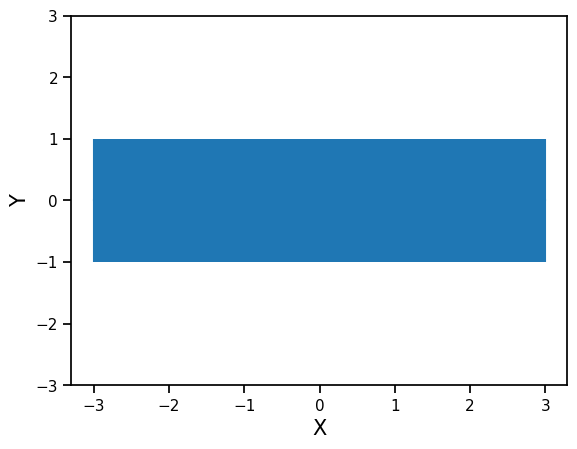

In [6]:
θ = [1, 0.10]
σ_0 = exponential_cov(0, 0, θ)
xpts = np.arange(-3, 3, step=0.01)
plt.errorbar(xpts, np.zeros(len(xpts)), yerr=σ_0, capsize=0)
plt.ylim(-3, 3);
plt.xlabel('X', fontsize= 15)
plt.ylabel('Y', fontsize= 15)
plt.show()

Let's select an arbitrary starting point to sample, say $x=1$. Since there are no prevous points, we can sample from an unconditional Gaussian:

In [7]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]

In [2]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
y_data

NameError: name 'σ_0' is not defined

We can now update our confidence band, given the point that we just sampled, using the covariance function to generate new point-wise intervals, conditional on the value $[x_0, y_0]$.

In [ ]:
σ_1 = exponential_cov(x_data, x_data, θ)

In [8]:
def predict(x, data, kernel, params, sigma, t):
    k = [kernel(x, y, params) for y in data]
    Sinv = np.linalg.inv(sigma)
    y_pred = np.dot(k, Sinv).dot(t)
    sigma_new = kernel(x, x, params) - np.dot(k, Sinv).dot(k)
    return y_pred, sigma_new

In [ ]:
x_pred = np.linspace(-3, 3, 1000)
predictions = [predict(i, x_data, exponential_cov, θ, σ_1, y_data) for i in x_pred]

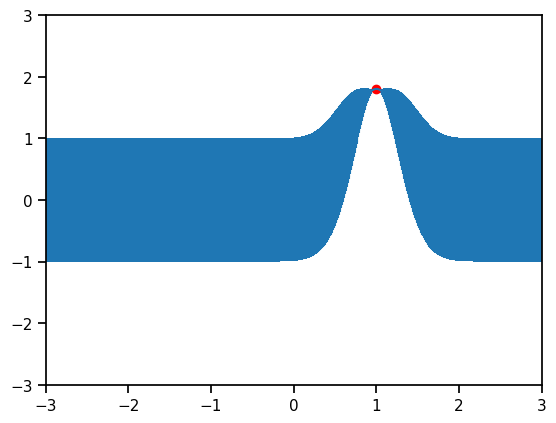

In [ ]:
y_pred, sigmas = np.transpose(predictions)
plt.errorbar(x_pred, y_pred, yerr=sigmas, capsize=0)
plt.plot(x_data, y_data, "ro")
plt.xlim(-3, 3); plt.ylim(-3, 3);

So conditional on this point, and the covariance structure we have specified, we have essentially constrained the probable location of additional points. Let's now sample another:

In [10]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
m, s = conditional([-0.7], x_data, y_data, θ)
y2 = np.random.normal(m, s)


This point is added to the realization, and can be used to further update the location of the next point.

In [11]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
m, s = conditional([-0.7], x_data, y_data, θ)
y2 = np.random.normal(m, s)
x_data.append(-0.7)
y_data.append(y2)

In [ ]:
σ_2 = exponential_cov(x_data, x_data, θ)

predictions = [predict(i, x_data, exponential_cov, θ, σ_2, y_data) for i in x_pred]

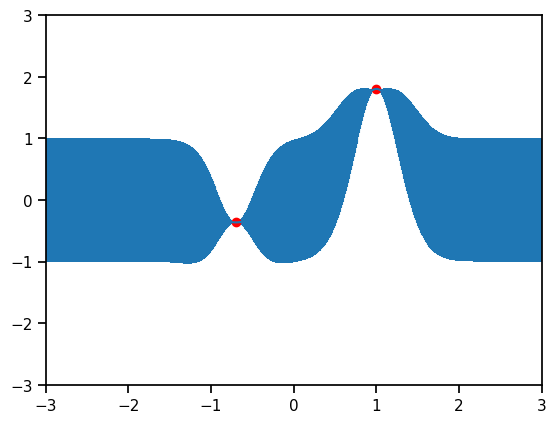

In [ ]:
y_pred, sigmas = np.transpose(predictions)
plt.errorbar(x_pred, y_pred, yerr=sigmas, capsize=0)
plt.plot(x_data, y_data, "ro")
plt.xlim(-3, 3); plt.ylim(-3, 3);

Of course, sampling sequentially is just a heuristic to demonstrate how the covariance structure works. We can just as easily sample several points at once:

In [ ]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
m, s = conditional([-0.7], x_data, y_data, θ)
y2 = np.random.normal(m, s)
x_data.append(-0.7)
y_data.append(y2)
x_more = [-1.1, -1.5, 0.3, 1.8, 0.5]
mu, s = conditional(x_more, x_data, y_data, θ)
y_more = np.random.multivariate_normal(mu, s)
y_more

array([-0.65203094, -0.67603918, -0.46378881,  0.89638984,  0.35823343])

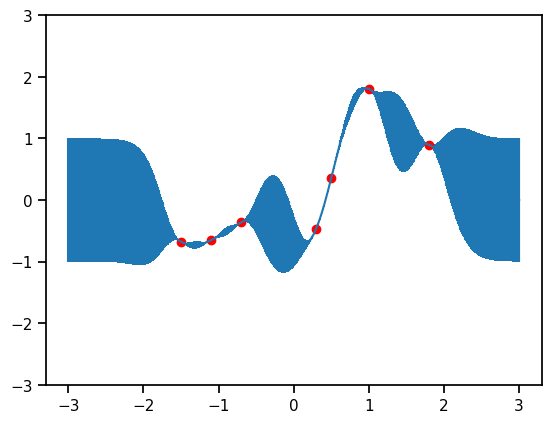

In [ ]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
m, s = conditional([-0.7], x_data, y_data, θ)
y2 = np.random.normal(m, s)
x_data.append(-0.7)
y_data.append(y2)
x_more = [-1.1, -1.5, 0.3, 1.8, 0.5]
mu, s = conditional(x_more, x_data, y_data, θ)
y_more = np.random.multivariate_normal(mu, s)

x_data += x_more
y_data += y_more.tolist()

σ_new = exponential_cov(x_data, x_data, θ)

predictions = [predict(i, x_data, exponential_cov, θ, σ_new, y_data) for i in x_pred]

y_pred, sigmas = np.transpose(predictions)
plt.errorbar(x_pred, y_pred, yerr=sigmas+0.00001, capsize=0)
plt.plot(x_data, y_data, "ro")
plt.ylim(-3, 3);

So as the density of points becomes high, the result will be one realization (function) from the prior GP.

This example, of course, is trivial because it is simply a random function drawn from the prior. What we are really interested in is *learning* about an underlying function from information residing in our data. In a parametric setting, we either specify a likelihood, which we then maximize with respect to the parameters, of a full probability model, for which we calculate the posterior in a Bayesian context. Though the integrals associated with posterior distributions are typically intractable for parametric models, they do not pose a problem with Gaussian processes.

## Gaussian processes regression

The following simulated data clearly shows some type of non-linear process, corrupted by a certain amount of observation or measurement error so it should be a reasonable task for a Gaussian process approach.

In [12]:
x_data = [1.]
y_data = [np.random.normal(scale=σ_0)]
m, s = conditional([-0.7], x_data, y_data, θ)
y2 = np.random.normal(m, s)
x_data.append(-0.7)
y_data.append(y2)
x_more = [-1.1, -1.5, 0.3, 1.8, 0.5]
mu, s = conditional(x_more, x_data, y_data, θ)
y_more = np.random.multivariate_normal(mu, s)

x_data += x_more
y_data += y_more.tolist()

x_data, y_data

([1.0, -0.7, -1.1, -1.5, 0.3, 1.8, 0.5],
 [0.14260259031658618,
  0.5596903573212673,
  1.0516216641708465,
  0.21078243533740593,
  -1.0799953048727609,
  2.523299481622379,
  -1.162276101398482])

## Marginal Likelihood Implementation

The `gp.Marginal` class in PyMC implements the simplest case of GP regression:  the observed data are the sum of a GP and Gaussian noise.  `gp.Marginal` has a `marginal_likelihood` method, and a `conditional` method.  Given a mean and covariance function, the function $f(x)$ is modeled as,

$$
f(x) \sim \mathcal{GP}(m(x),\, k(x, x')) \,.
$$

The observations $y$ are the unknown function plus noise

$$
\begin{aligned}
  \epsilon &\sim N(0, \Sigma) \\
  y &= f(x) + \epsilon \\
\end{aligned}
$$


### Choosing parameters

This is relevant because we have to make choices regarding the parameters of our Gaussian process; they were chosen arbitrarily for the random functions we demonstrated above.

For example, in the squared exponential covariance function, we must choose two parameters:

$$k\left(x, x^{\prime}\right)=\sigma^2 \exp \left[-\frac{\left(x-x^{\prime}\right)^{2}}{2 \ell^{2}}\right]$$

The first parameter $\sigma$ is a scale parameter, which allows the function to yield values outside of the unit interval. The second parameter $\ell$ is a length scale parameter that determines the degree of covariance between $x$ and $x^{\prime}$; larger values will tend to smooth the function relative to larger values.

We can use the **marginal likelihood** to select appropriate values for these parameters, since it trades off model fit with model complexity. Thus, an optimization procedure can be used to select values for $\theta = (\sigma, \ell)$ that maximize the marginial likelihood.

### Covariance functions

The behavior of individual realizations from the GP is governed by the covariance function. This function controls both the degree of *shrinkage* to the mean function and the *smoothness* of functions sampled from the GP.

PyMC includes a [library of covariance functions](https://docs.pymc.io/notebooks/GP-MeansAndCovs.html) to choose from. A flexible choice to start with is the Mat&#232;rn covariance.

$$k(x-x^{\prime}) = \frac{\sigma^2}{\Gamma(\nu)2^{\nu-1}} \left(\frac{\sqrt{2 \nu (x-x^{\prime})^2}}{\ell}\right)^{\nu} K_{\nu}\left(\frac{\sqrt{2 \nu (x-x^{\prime})^2}}{\ell}\right)$$

where where $\Gamma$ is the gamma function and $K$ is a modified Bessel function. The form of covariance matrices sampled from this function is governed by three parameters, each of which controls a property of the covariance.

* **amplitude** ($\sigma$) controls the scaling of the output along the y-axis. This parameter is just a scalar multiplier, and is therefore usually left out of implementations of the Mat&#232;rn function (*i.e.* set to one)

* **lengthscale** ($l$) complements the amplitude by scaling realizations on the x-axis. Larger values make points appear closer together.

* **roughness** ($\nu$) controls the sharpness of ridges in the covariance function, which ultimately affect the roughness (smoothness) of realizations.

Though in general all the parameters are non-negative real-valued, when $\nu = p + 1/2$ for integer-valued $p$, the function can be expressed partly as a polynomial function of order $p$ and generates realizations that are $p$-times differentiable, so values $\nu \in \{3/2, 5/2\}$ are extremely common.

To provide an idea regarding the variety of forms or covariance functions, here's small selection of available ones:

## The matern kernel:

## $$
k_\nu(d) = \sigma^2 \frac{2^{1-\nu}}{\Gamma(\nu)} \left( \frac{\sqrt{2\nu}d}{\ell} \right)^\nu K_\nu \left( \frac{\sqrt{2\nu}d}{\ell} \right)
 $$

where,

* $d = ||x-y||$ is the Euclidean distance between the input points
* $\nu$ is the smoothness parameter
* $\ell$ is the length scale parameter
* $sigma^2$   is the variance parameter
* $\Gamma(\dot)$ is the Gamma function

## That is very complicated!

### Lets insert values of $\nu$ to simpliy things.

##  For $ \nu = 3/2 $ we get:

## Matern 3/2 kernel

### $$ k(x,y) = \sigma^2 \left(1+\frac{\sqrt{3}d}{l}\right) exp\left(-\frac{\sqrt{3}d}{l}\right) $$

## $$ d= || x-y|| $$

## Summary:

### We learned about 4 types of kernels.


### 1. Matern 3/2 - to be used for more jagged data and less smooth.

### 2. Matern 5/2 - to be used for more smooth data than the  Matern 3/2.

### 3. Quadratic exponential - smoother than both of the above.

### 4. Suited for cyclic data.


## Marginal Gaussian Processes

Now that we have a general idea about covariance functions, let's begin by defining one for our first model.

We can use a Matern(5/2) covariance to model our simulated data, and pass this as the `cov_func` argument to the `Marginal` class.

### Suppose how I choose a kernel, that's not enough I still need to specify its parameters.

### For this purpose we will follow the same Bayesain procedure we had before. For each parameter I will give a prior and conduct a Bayesian procedure.

## This how our data looks like, and we wish to create a GP regression
### We need to decide on which kernel type we wish to use.
### Each kernel has parameters, and we fit thier best values using the Bayesian method.
### That is, we insert a prior for each one and then compute its posterior.
### We need to follow 7 steps:

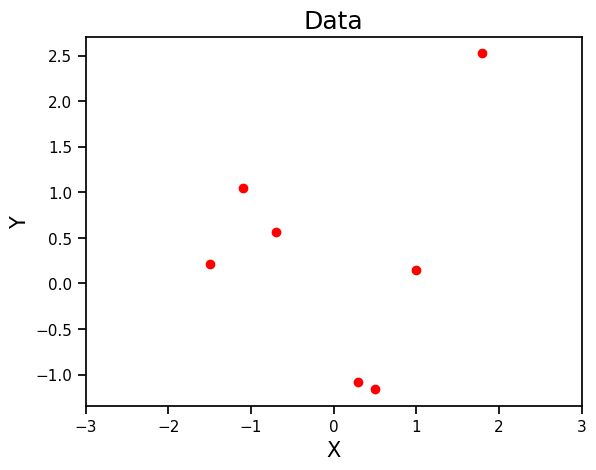

In [13]:
plt.figure()
plt.plot(x_data, y_data, 'ro')
plt.xlabel('X', fontsize = 15)
plt.ylabel('Y', fontsize = 15)
plt.title('Data', fontsize = 18)
plt.xlim(-3,3)
plt.show()

## Defining a pymc GP model:
### Lets do it buttom to up

### 1. Sampling the posterior
### 2. Defining the likelihood: using gp.marginal_likelihood
### 3. Defining prior to the noise parameter
### 4. Defining the Pymc gp object: this includes both mean function and covariance function
### 5. defining the mean function
### 6. defining the covariance function
### 7. defining prior of the cov functions

In [14]:
with pm.Model() as model:

    # 7
    ℓ = pm.Gamma("ℓ", alpha=2, beta=1)
    η = pm.HalfCauchy("η", beta=5)
    #################################
    # 6
    cov = η**2 * pm.gp.cov.Matern52(1, ℓ)
    #################################
    # 5
    mean = pm.gp.mean.Constant(c=1)
    #################################
    # 4
    gp = pm.gp.Marginal(mean_func=mean, cov_func=cov)
    #################################
    # 3
    σ = pm.HalfCauchy("σ", beta=5)
    #################################
    # 2
    obs = gp.marginal_likelihood("obs", X=np.array(x_data).reshape(-1, 1), y=np.array(y_data), noise=σ)
    #################################
    # 1
    marginal_post = pm.sample()
    #################################


Output()

ERROR:pymc.stats.convergence:There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


We can collect the results into a pandas dataframe to display

In [16]:
pm.summary(marginal_post).round(2)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
η,2.40,1.84,0.01,5.67,0.10,0.19,394.0,293.0,1.01
σ,0.68,0.63,0.00,1.77,0.02,0.03,601.0,438.0,1.00
ℓ,1.52,0.93,0.20,3.18,0.04,0.04,588.0,827.0,1.00


## How do we make predictions over the values we interested in?


### The `.conditional` distribution

In addition to fitting the model, we would like to be able to generate predictions. This implies sampling from the posterior predictive distribution, which if you recall is just some linear algebra:

$$\begin{aligned}
m^*(x^*) &= k(x^*,x)^T[k(x,x) + \sigma^2I]^{-1}y \\
k^*(x^*) &= k(x^*,x^*)+\sigma^2 - k(x^*,x)^T[k(x,x) + \sigma^2I]^{-1}k(x^*,x)
\end{aligned}$$

PyMC allows for predictive sampling after the model is fit, using the recorded values of the model parameters to generate samples. The `conditional` method implements the predictive GP above, called with a grid of points over which to generate realizations:

The `.conditional` has an optional flag for `pred_noise`, which defaults to `False`.  When `pred_noise=False`, the `conditional` method produces the predictive distribution for the underlying function represented by the GP.  When `pred_noise=True`, the `conditional` method produces the predictive distribution for the GP plus noise.  

If using an additive GP model, the conditional distribution for individual components can be constructed by setting the optional argument `given`.  

We can define a grid of new values from `x=-3` to `x=3`, then add the GP conditional to the model, given the new X values:



In [17]:
X_new = np.linspace(-3, 3, 100)[:,None]

with model:
    f_pred = gp.conditional("f_pred", X_new)

We can draw samples from the posterior predictive distribution over the specified grid of values.

In [18]:
with model:
    pred_samples = pm.sample_posterior_predictive(marginal_post, var_names=['f_pred']) #

Output()

In [22]:
preds = az.extract(pred_samples.posterior_predictive)['f_pred'].values.transpose()

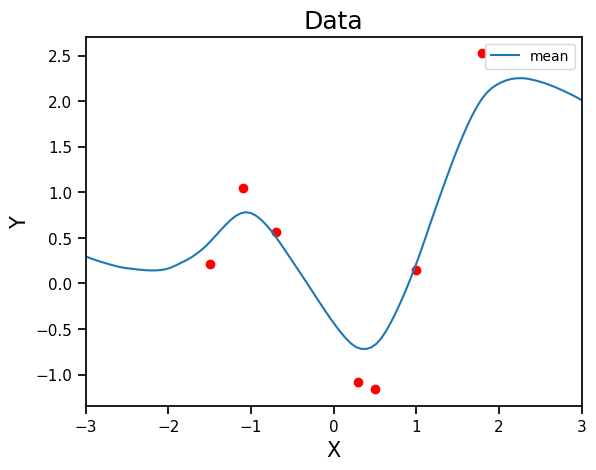

In [23]:
plt.figure()
plt.plot(x_data, y_data, 'ro')
plt.plot(X_new,preds.mean(axis = 0), label = 'mean')
plt.xlabel('X', fontsize = 15)
plt.ylabel('Y', fontsize = 15)
plt.title('Data', fontsize = 18)
plt.legend(fontsize=10)
plt.xlim(-3,3)
plt.show()



### What is the probability that the posterior in $x=0$ will be less than 0?

In [24]:
(preds[:, 50]<0).mean()

np.float64(0.768)

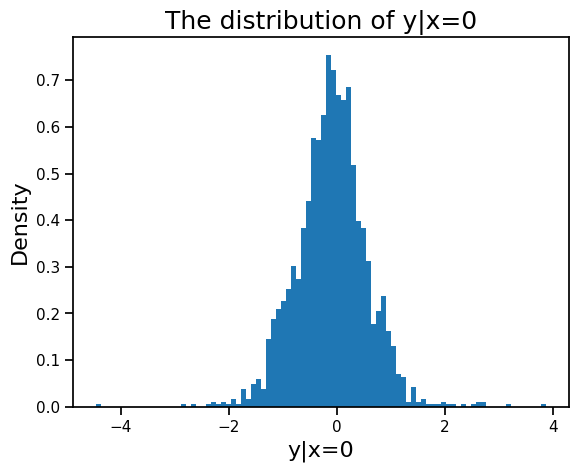

In [ ]:
plt.figure()
plt.hist(preds[:, 50], density = True, bins = 90)
plt.title('The distribution of y|x=0', fontsize= 18)
plt.xlabel('y|x=0', fontsize = 16)
plt.ylabel('Density', fontsize = 16)
plt.show()